# A battery on your own scored sample: contract 1, run_suite and the lights

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- put a CSV of scored obligors through contract 1 and read what it accepts, flags and rejects, and why it never coerces a value;
- map PDs to the master scale and build the grade table the grade-level tests read;
- run a battery of engine tests under one policy with `run_suite`, which never stops at the first failure, and read its table of lights;
- explain why the level tests and the stability test are red on the current sample while the ranking test is green, and why the calibrated development sample is green on every level test;
- check that this notebook's battery gives the same numbers as the pipeline's own door, `data-pipeline/validate.py`.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

This notebook also imports two readers of the product's pipeline: contract 1 (`pipeline.io.contract`) and the master scale (`pipeline.core.calibration`). The pipeline is plain scripts, not a package, so the notebook puts `data-pipeline/` on the import path and imports them from there: one reader for the pipeline, the tests and these notebooks, never a copy. The next cell does it and prints the versions.

In [1]:
# Put the pipeline on the import path, import the readers and the engine, and print the package versions
import importlib.metadata as md
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.core.calibration import GRADES, MASTER_SCALE_UPPER, grade_table
from pipeline.io import contract
from pipeline.io.formats import read_csv_rows

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Data

The same two synthetic samples with a known truth as in notebook 03, committed in `data/examples/` (owner: this repository; no third-party licence, MIT; generated from a seed by `data-pipeline/pipeline/io/examples.py`):

- `scored_sample_development.csv`: 2,000 obligors on 2024-12-31, PDs calibrated by construction. It plays the part of the **development sample**, the reference a validator compares against.
- `scored_sample_current.csv`: 2,000 obligors on 2025-12-31 from a riskier population whose defaults arrive at 1.5 times the PD. It is the **sample under validation**.

Your own model enters the same way: a CSV with `id`, `observation_date`, `target` and `pd`, one row per obligor. The shape is the `scored_sample` family of contract 1 (`docs/guides/02_validate-your-own-model.md`).

## Method

### Step 1: contract 1 reads, flags and rejects; it never coerces

Contract 1 parses every value by its declared kind. A PD of 1.2, a target of `yes` or a second row with the same identifier on the same date is **rejected** with the field, the value and what was expected; a value that is odd but usable is **flagged**; a column the family does not declare is listed as **ignored** and never used. Nothing is silently repaired, because a repaired value is a number the validator did not see. The next cell first shows the rule on five rows written in the cell, three of them wrong.

In [2]:
# Five rows written by hand: two valid, three that contract 1 must reject (a PD of 1.2, a target of "yes", a repeated identifier)
planted = [
    {"id": "A1", "observation_date": "2025-12-31", "target": "0", "pd": "0.05", "segment": "retail"},
    {"id": "A2", "observation_date": "2025-12-31", "target": "1", "pd": "1.2", "segment": "retail"},
    {"id": "A3", "observation_date": "2025-12-31", "target": "yes", "pd": "0.30", "segment": "retail"},
    {"id": "A1", "observation_date": "2025-12-31", "target": "1", "pd": "0.10", "segment": "retail"},
    {"id": "A5", "observation_date": "2025-12-31", "target": "1", "pd": "0.20", "segment": "retail", "extra": "x"},
]
report = contract.validate("scored_sample", planted)
print("counts:", report.counts())
print("ignored columns:", report.ignored_columns)
for example in report.examples():
    print(f'{example["kind"]:9s} row {example["row"]} field {example["field"]:4s} value {example["value"]!s:5s} expected: {example["expected"]} | reason: {example["reason"]}')

counts: {'input': 5, 'accepted': 2, 'rejected': 3, 'flagged': 0, 'excluded': 0}
ignored columns: ['extra']
rejected  row 1 field pd   value 1.2   expected: a finite number in (0, 1) (probability) | reason: out of range
rejected  row 2 field target value yes   expected: 0 or 1 | reason: not 0 or 1
rejected  row 3 field id   value A1    expected: Each identifier appears once per observation date. | reason: duplicate of an earlier record


Now the two real files. `read_csv_rows` reads the text without interpreting it, `contract.validate` applies the family, and the arrays the battery needs come from the **accepted** records only.

In [3]:
# Read both files through contract 1 and keep the accepted records as arrays
samples = {}
for name in ("development", "current"):
    rows = read_csv_rows(ROOT / "data" / "examples" / f"scored_sample_{name}.csv")
    checked = contract.validate("scored_sample", rows)
    samples[name] = (np.array([r["pd"] for r in checked.accepted]), np.array([r["target"] for r in checked.accepted]))
    print(f"{name:12s} contract 1 counts: {checked.counts()}")

pd_dev, y_dev = samples["development"]
pd_cur, y_cur = samples["current"]
print("current: defaults", int(y_cur.sum()), "| expected", round(float(pd_cur.sum()), 1))
print("development: defaults", int(y_dev.sum()), "| expected", round(float(pd_dev.sum()), 1))

development  contract 1 counts: {'input': 2000, 'accepted': 2000, 'rejected': 0, 'flagged': 0, 'excluded': 0}
current      contract 1 counts: {'input': 2000, 'accepted': 2000, 'rejected': 0, 'flagged': 0, 'excluded': 0}
current: defaults 207 | expected 138.1
development: defaults 100 | expected 111.2


### Step 2: the master scale and the grade table

Rating-style tests do not read one PD per obligor. They read **grades**: groups of obligors with similar risk, each with its count, its defaults and its mean PD. Contraste maps PDs to a geometric master scale (upper bounds 1% times 1.5 to the power k for k = 0 to 10, then 100%: twelve grades). The next cell builds the grade table of the current sample, drops the empty grades and prints it.

In [4]:
# Build the grade table of the current sample and print the non-empty grades
print("grades:", len(GRADES), "| first upper bounds:", [round(b, 4) for b in MASTER_SCALE_UPPER[:4]])
table = [g for g in grade_table(pd_cur, y_cur) if g["n"] > 0]
print(f'{"grade":6s} {"upper":>7s} {"n":>5s} {"defaults":>9s} {"mean PD":>8s} {"rate":>7s}')
for g in table:
    print(f'{g["grade"]:6s} {g["hi"]:7.4f} {g["n"]:5d} {g["d"]:9d} {g["pd"]:8.4f} {g["dr"]:7.4f}')

grades: 12 | first upper bounds: [0.01, 0.015, 0.0225, 0.0338]
grade    upper     n  defaults  mean PD    rate
G01     0.0100   189         1   0.0052  0.0053
G02     0.0150   115         1   0.0125  0.0087
G03     0.0225   155         3   0.0188  0.0194
G04     0.0338   207         6   0.0278  0.0290
G05     0.0506   290        22   0.0419  0.0759
G06     0.0759   352        25   0.0626  0.0710
G07     0.1139   317        48   0.0926  0.1514
G08     0.1709   233        49   0.1388  0.2103
G09     0.2563   121        43   0.2039  0.3554
G10     0.3844    20         9   0.3002  0.4500
G11     0.5767     1         0   0.4619  0.0000


### Step 3: a battery of tests, one policy

A battery is a list of tasks, each a pair of a test function and its arguments. `run_suite` runs them in order under one policy, and gives every `TestResult` the same model identifier and segment. The tasks below are the ones a validator runs on a PD model:

| Test | What it asks | Reference |
|---|---|---|
| `disc.auc` | does the PD rank defaulters above non-defaulters? | ECB 2019, Annex 1 (section 3.1) |
| `disc.auc_vs_initial` | has the ranking deteriorated since development (one-sided)? | ECB 2019, section 2.5.4.1 |
| `pd.jeffreys`, `pd.binomial` | is the portfolio PD too low? | ECB 2019; BCBS WP14 |
| `pd.binomial_vasicek` | the same, allowing for a one-factor default correlation (rho = 0.04, the Basel retail revolving value) | BCBS WP14 |
| `pd.chi2_grades` | do the defaults of all grades match their PDs? | BCBS WP14 |
| `pd.hosmer_lemeshow`, `pd.spiegelhalter` | do the obligor-level PDs match the outcomes? | Hosmer and Lemeshow 1980; Spiegelhalter 1986 |
| `stability.psi` | has the PD distribution moved since development, against the chi-square benchmark? | Yurdakul and Naranjo 2020 |

Tests that compare with the development need it as the reference: the AUC at development (with its variance), and the ten quantile bins of the development PDs for the PSI. The next cell defines a small function that lists the tasks for a sample and an optional reference. The function chooses which engine tests to call and with which arrays; every statistic is computed by the engine.

In [5]:
# List the engine tasks for a sample; the engine computes every statistic, this function only chooses the calls
from riskvalidation.validation import calibration as cal
from riskvalidation.validation import discrimination as disc
from riskvalidation.validation import stability as st

RETAIL_REVOLVING_RHO = 0.04


def battery_tasks(pd_eval, y_eval, reference=None):
    # The inputs of the level tests: the non-empty grades of the master scale and the totals of the portfolio
    grades = [g for g in grade_table(pd_eval, y_eval) if g["n"] > 0]
    n_obligors, n_defaults, mean_pd = len(y_eval), int(y_eval.sum()), float(pd_eval.mean())
    # The ranking test needs only the sample
    tasks = [(disc.disc_auc, dict(risk=pd_eval, defaults=y_eval))]
    # With a reference: the AUC against the development carries the development AUC's own variance
    if reference is not None:
        pd_ref, y_ref = reference
        auc_ref, variance_ref, *_ = disc.auc_with_variance(pd_ref, y_ref)
        tasks.append((disc.disc_auc_vs_initial, dict(auc_initial=float(auc_ref), risk=pd_eval, defaults=y_eval, auc_initial_variance=float(variance_ref))))
    # The level and fit tests need only the sample
    tasks += [
        (cal.pd_jeffreys, dict(n=n_obligors, d=n_defaults, pd=mean_pd)),
        (cal.pd_binomial, dict(n=n_obligors, d=n_defaults, pd=mean_pd)),
        (cal.pd_binomial_vasicek, dict(n=n_obligors, d=n_defaults, pd=mean_pd, rho=RETAIL_REVOLVING_RHO)),
        (cal.pd_chi2_grades, dict(n=[g["n"] for g in grades], d=[g["d"] for g in grades], pd=[g["pd"] for g in grades])),
        (cal.pd_hosmer_lemeshow, dict(defaults=y_eval, pd=pd_eval, fitted=False)),
        (cal.pd_spiegelhalter, dict(defaults=y_eval, pd=pd_eval)),
    ]
    # With a reference: the PSI bins are the deciles of the development PDs, fixed before the current sample is seen
    if reference is not None:
        edges = st.quantile_edges(pd_ref, 10)
        tasks.append((st.stability_psi, dict(expected_counts=st.bin_counts(pd_ref, edges), actual_counts=st.bin_counts(pd_eval, edges))))
    return tasks


current_tasks = battery_tasks(pd_cur, y_cur, reference=(pd_dev, y_dev))
print("tasks:", [func.__name__ for func, _ in current_tasks])

tasks: ['disc_auc', 'disc_auc_vs_initial', 'pd_jeffreys', 'pd_binomial', 'pd_binomial_vasicek', 'pd_chi2_grades', 'pd_hosmer_lemeshow', 'pd_spiegelhalter', 'stability_psi']


Two choices deserve a remark. `fitted=False` tells Hosmer-Lemeshow that the PDs were not fitted on this sample, so it uses as many degrees of freedom as groups (a fitted model would use two fewer). And the AUC against the development is a one-sided test (it rejects only when the AUC fell), and it carries the development AUC's own variance: ignoring it makes the test reject more often than its nominal level when nothing changed.

Now the run. `run_suite` takes the tasks, the policy and the identifiers.

In [6]:
# Run the battery under the default policy and read the counts and the worst light
from riskvalidation import run_suite

policy = rv.default_policy()
suite = run_suite(current_tasks, policy=policy, model_id="own-model", segment="portfolio")
print("policy:", suite.policy_version)
print("results:", len(suite.results))
print("counts:", suite.counts())
print("worst light:", suite.worst().value)

policy: riskvalidation-default 2026.10.1
results: 9
counts: {'green': 2, 'amber': 0, 'red': 6, 'not_evaluated': 1, 'error': 0}
worst light: red


### Step 4: read the table of lights

One row per test, with its p-value, its metric (when it has one) and the light. The next cell prints it in the order of the battery.

In [7]:
# Print the table of lights: p-value, metric and light
def lights_table(run):
    print(f"{'test':22s} {'p-value':>12s} {'metric':>10s}  light")
    for result in run.results:
        p_text = "-" if result.p_value is None else format(result.p_value, ".4g")
        m_text = "-" if result.metric is None else format(result.metric, ".4f")
        print(f"{result.test_id:22s} {p_text:>12s} {m_text:>10s}  {result.light.value}")


lights_table(suite)

test                        p-value     metric  light
disc.auc                          -     0.7791  not_evaluated
disc.auc_vs_initial          0.9142          -  green
pd.jeffreys               6.047e-09          -  red
pd.binomial               7.591e-09          -  red
pd.binomial_vasicek          0.1139          -  green
pd.chi2_grades            2.648e-07          -  red
pd.hosmer_lemeshow        3.872e-09          -  red
pd.spiegelhalter          3.645e-09          -  red
stability.psi             4.211e-10     0.0626  red


### Step 5: the PSI, opened

The PSI compares the share of each sample in $B$ bins fixed on the development sample. With $E_i$ and $A_i$ the counts of the development and the current sample in bin $i$, $n = \sum_i E_i$, $m = \sum_i A_i$, $e_i = E_i / n$ and $a_i = A_i / m$:

$$\mathrm{PSI} = \sum_{i=1}^{B} (a_i - e_i)\,\ln\frac{a_i}{e_i}$$

An empty bin is floored at half an observation of its sample, so the logarithm stays finite. The usual reading of the PSI is a rule of thumb (0.10 and 0.25) used without reference to error rates. Yurdakul and Naranjo (2020, doi:10.21314/JRMV.2020.227) show that, scaled by the two sample sizes, the PSI follows a chi-square distribution with $B - 1$ degrees of freedom when nothing changed:

$$\left(\frac{1}{n} + \frac{1}{m}\right)^{-1}\mathrm{PSI} \;\approx\; \chi^2_{B-1}$$

which gives a p-value (the upper tail) and a critical PSI at level $\alpha$:

$$\mathrm{PSI}_{\mathrm{crit}} = \left(\frac{1}{n} + \frac{1}{m}\right)\chi^2_{1-\alpha,\,B-1}$$

The engine's light follows that p-value. The ten bins are the deciles of the development PDs, so the development sample has 200 obligors in each. The next cell counts the current sample in the same bins.

In [8]:
# The ten bins are the deciles of the development PDs; count how many obligors of each sample fall in each bin
edges = st.quantile_edges(pd_dev, 10)
expected_counts = st.bin_counts(pd_dev, edges)
actual_counts = st.bin_counts(pd_cur, edges)
print("development counts per bin:", expected_counts.tolist())
print("current counts per bin:    ", actual_counts.tolist())

development counts per bin: [200, 200, 200, 200, 200, 200, 200, 200, 200, 200]
current counts per bin:     [136, 176, 152, 168, 200, 202, 190, 217, 218, 341]


The engine's result carries what the statistic is made of. The next cell reads it from the PSI row of the suite: the PSI and its contribution per bin, the scale $1/n + 1/m$, the scaled statistic, its p-value and the critical PSI at 5%.

In [9]:
# The PSI row of the suite: the statistic, its scale, the scaled statistic, the p-value and the critical PSI at 5%
psi = next(r for r in suite.results if r.test_id == "stability.psi")
n_dev, n_cur = psi.extras["n"], psi.extras["m"]
scale = 1 / n_dev + 1 / n_cur
print("PSI:", round(psi.metric, 6), "| bins:", psi.extras["bins"])
print("contribution per bin:", [round(c, 4) for c in psi.extras["contributions"]])
print("scale 1/n + 1/m:", scale)
print("scaled statistic PSI / scale:", round(psi.metric / scale, 3), "| degrees of freedom:", psi.extras["bins"] - 1)
print("p-value:", format(psi.p_value, ".4g"))
print("critical PSI at 5%:", round(psi.extras["benchmark_05"], 4), "| conventional band:", psi.extras["band"])

PSI: 0.062603 | bins: 10
contribution per bin: [0.0123, 0.0015, 0.0066, 0.0028, 0.0, 0.0, 0.0003, 0.0007, 0.0008, 0.0376]
scale 1/n + 1/m: 0.001
scaled statistic PSI / scale: 62.603 | degrees of freedom: 9
p-value: 4.211e-10
critical PSI at 5%: 0.0169 | conventional band: little change


### Step 6: Hosmer-Lemeshow, opened

The Hosmer-Lemeshow test (Hosmer and Lemeshow, 1980) sorts the obligors by PD, cuts them into $G$ groups of equal size and compares, in each group $g$, the observed defaults $O_g$ with the expected defaults $E_g$ (the sum of the PDs of its $m_g$ obligors):

$$\mathrm{HL} = \sum_{g=1}^{G} \frac{(O_g - E_g)^2}{E_g\,(1 - E_g / m_g)}$$

The reference distribution is chi-square, and its degrees of freedom depend on where the PDs came from:

$$\mathrm{HL} \sim \chi^2_{G} \quad \text{(PDs given before the outcomes)}, \qquad \mathrm{HL} \sim \chi^2_{G-2} \quad \text{(PDs fitted on these same observations)}$$

A validation sample is the first case, which is why the battery sets `fitted=False` and the engine uses $G = 10$ degrees of freedom. The next cell reads the statistic from the suite.

In [10]:
# Hosmer-Lemeshow on the current sample: the statistic, the groups and the degrees of freedom the engine used
hl = next(r for r in suite.results if r.test_id == "pd.hosmer_lemeshow")
print("HL statistic:", round(hl.statistic, 3), "| groups:", hl.extras["groups"])
print("degrees of freedom:", hl.extras["dof"], "| fitted:", hl.extras["fitted"])
print("p-value:", format(hl.p_value, ".4g"))

HL statistic: 59.848 | groups: 10
degrees of freedom: 10 | fitted: False
p-value: 3.872e-09


The same statistic under the other rule: had the PDs been fitted on this very sample, the engine would use $G - 2 = 8$ degrees of freedom and give another p-value. The next cell shows how much the rule matters.

In [11]:
# The same statistic read under the other rule: PDs fitted on this very sample lose two degrees of freedom
hl_fitted = cal.pd_hosmer_lemeshow(defaults=y_cur, pd=pd_cur, fitted=True, policy=policy, model_id="own-model", segment="portfolio")
print("fitted=True | degrees of freedom:", hl_fitted.extras["dof"], "| p-value:", format(hl_fitted.p_value, ".4g"), "| light:", hl_fitted.light.value)

fitted=True | degrees of freedom: 8 | p-value: 4.991e-10 | light: red


### Step 7: the chi-square over grades, opened

The test over grades (BCBS Working Paper 14) takes the $K$ non-empty grades of the master scale, with $n_i$ obligors, $d_i$ defaults and mean PD $p_i$ in grade $i$:

$$T = \sum_{i=1}^{K} \frac{(n_i p_i - d_i)^2}{n_i\,p_i\,(1 - p_i)} \;\sim\; \chi^2_{K}$$

The degrees of freedom are the number of grades, not the number of grades minus a fitted count, because the PDs of a master scale are given. The engine notes that the test is likely to understate the type I error under default dependence. The next cell reads the statistic and the degrees of freedom from the suite.

In [12]:
# The chi-square over grades of the suite: the statistic, the number of grades it counts and the p-value
chi = next(r for r in suite.results if r.test_id == "pd.chi2_grades")
print("T:", round(chi.statistic, 3), "| grades counted (non-empty):", chi.extras["dof"])
print("degrees of freedom:", chi.extras["dof"], "| p-value:", format(chi.p_value, ".4g"))

T: 52.07 | grades counted (non-empty): 11
degrees of freedom: 11 | p-value: 2.648e-07


### Step 8: the calibrated sample, alone

A battery is only convincing if it leaves a right model alone. The development sample is calibrated by construction. The level tests do not need a reference, so we run the tasks without one: no AUC against the initial and no PSI, which would compare a sample with itself.

In [13]:
# Run the level and fit tests on the development sample alone
alone = run_suite(battery_tasks(pd_dev, y_dev), policy=policy, model_id="own-model", segment="portfolio")
lights_table(alone)
print("counts:", alone.counts())

test                        p-value     metric  light
disc.auc                          -     0.7426  not_evaluated
pd.jeffreys                  0.8629          -  green
pd.binomial                  0.8737          -  green
pd.binomial_vasicek          0.5401          -  green
pd.chi2_grades               0.5088          -  green
pd.hosmer_lemeshow           0.6875          -  green
pd.spiegelhalter             0.8311          -  green
counts: {'green': 6, 'amber': 0, 'red': 0, 'not_evaluated': 1, 'error': 0}


### Step 9: a suite never stops at the first failure

A validator needs the whole picture, so a test that raises is recorded as an `error` result with the exception text, and the remaining tests still run. The next cell adds a task that must fail (the Jeffreys test on a portfolio of zero obligors) in the middle of the battery.

In [14]:
# Insert a task that must fail and show that the suite records it and finishes
broken = [current_tasks[0], (cal.pd_jeffreys, dict(n=0, d=0, pd=0.05)), current_tasks[3]]
mixed = run_suite(broken, policy=policy, model_id="own-model", segment="portfolio")
for result in mixed.results:
    print(f"{result.test_id:14s} {result.light.value:14s} {result.notes}")
print("counts:", mixed.counts(), "| worst:", mixed.worst().value)

disc.auc       not_evaluated  policy riskvalidation-default 2026.10.1 holds no thresholds for this test; no light assigned
pd.jeffreys    error          ValueError: the Jeffreys test needs at least one obligor
pd.binomial    red            assumes independent defaults; WP14: the true type I error can be much larger if defaults are correlated
counts: {'green': 0, 'amber': 0, 'red': 1, 'not_evaluated': 1, 'error': 1} | worst: error


### Step 10: the same numbers as the product's door

`data-pipeline/validate.py` is the command-line door for your own model. It runs the pipeline's full battery on a CSV with the same engine calls. The next cell calls its function on the same two files and checks that every test of the battery above has the same p-value or metric and the same light there.

In [15]:
# Compare the battery above with the report of the pipeline's own door on the same files (nothing is written)
from pipeline.own_sample import validate_own

examples = ROOT / "data" / "examples"
door = validate_own(examples / "scored_sample_current.csv", reference=examples / "scored_sample_development.csv", model_id="own-model")
door_rows = {(row["test_id"], row["segment"]): row for row in door["tests"]}

agree = []
for result in suite.results:
    row = door_rows[(result.test_id, "portfolio")]
    same_value = np.isclose(row["p_value"] if result.p_value is not None else row["metric"], result.p_value if result.p_value is not None else result.metric)
    agree.append(bool(same_value and row["light"] == result.light.value))
print("tests compared:", len(agree), "| all agree:", all(agree))
print("tests in the door's full battery:", len(door["tests"]), "| lights:", door["lights"])

tests compared: 9 | all agree: True
tests in the door's full battery: 24 | lights: {'green': 10, 'not_evaluated': 4, 'red': 10}


### Step 11: the evidence, drawn

The last cell draws what the level tests saw. For each grade of the master scale, the defaults the PDs expect (the sum of the PDs) and the defaults observed, for the development sample on the left and the current one on the right.

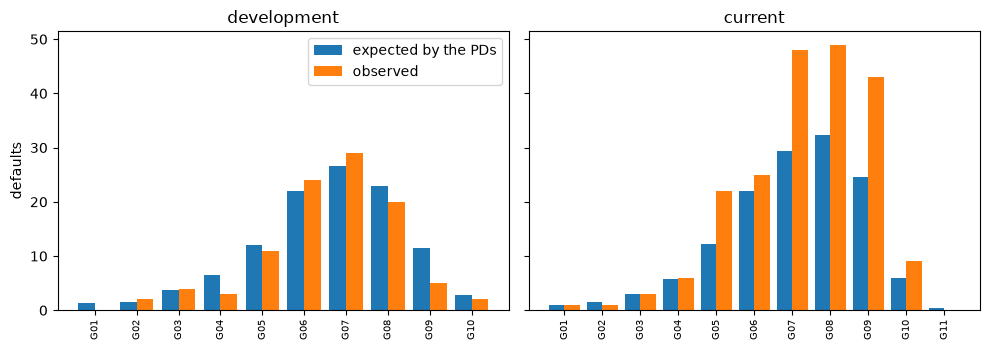

In [16]:
# Draw expected and observed defaults by grade for the two samples
LABELS = ("expected by the PDs", "observed")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (name, (pd_s, y_s)) in zip(axes, samples.items()):
    grades = [g for g in grade_table(pd_s, y_s) if g["n"] > 0]
    positions = np.arange(len(grades))
    expected = [g["pd"] * g["n"] for g in grades]
    ax.bar(positions - 0.2, expected, width=0.4, label=LABELS[0])
    ax.bar(positions + 0.2, [g["d"] for g in grades], width=0.4, label=LABELS[1])
    ax.set_xticks(positions)
    ax.set_xticklabels([g["grade"] for g in grades], rotation=90, fontsize=7)
    ax.set_title(name)
axes[0].set_ylabel("defaults")
axes[0].legend()
fig.tight_layout()
plt.show()

## Results

- **Contract 1 rejected exactly what it should.** Of the five rows written by hand, it rejected the PD of 1.2, the target `yes` and the repeated identifier, accepted the other two and listed the extra column as ignored. The two real files were accepted whole.
- **The current sample is found.** Six of the eight tests that have a threshold are red: the Jeffreys test, the binomial test, the chi-square over grades, Hosmer-Lemeshow, Spiegelhalter and the PSI. The cause is visible in the figure: from grade G05 to G10 the observed defaults exceed what the PDs expect, in the pattern of a level that is too low. The truth, defaults at 1.5 times the PD, is what the tests find.
- **The ranking is intact.** The AUC of the current sample (about 0.78) is not lower than the one on the development sample alone (about 0.74), and the test of the AUC against the initial is green. A model can rank as well as at development and be mis-sized: this is why the battery has level tests as well as discrimination tests.
- **The Vasicek-adjusted binomial is green.** With an asset correlation of 0.04, the excess of defaults of one period is compatible with a systematic shock, and one period cannot tell the two apart. The tests that assume independence are the more sensitive and the more likely to be wrong in the other direction. Here the truth is independent defaults at 1.5 times the PD, so the Vasicek green is a miss: the price of allowing for correlation is power. Each call of the engine returns one test, so the battery runs both to show the contrast.
- **The PSI is red although its value, 0.063, is inside the conventional 0.10 band.** The policy reads the PSI against the chi-square benchmark of Yurdakul and Naranjo, which at 2,000 obligors per sample detects a shift the rule of thumb misses (the 5% critical PSI is 0.0169, step 5).
- **The calibrated sample is left alone.** Every level test is green on the development sample.
- **The door agrees.** The pipeline's own function returns the same p-values, metrics and lights as the battery built in this notebook.

What the lights do not show: they are the default policy's reading, not a compliance verdict (notebook 03), and the samples are synthetic with a known truth, which real portfolios never have.

## Summary

- Contract 1 turns a CSV into accepted records and reports what it rejected, flagged or ignored; it never coerces a value.
- The master scale turns PDs into grades, and the grade table is the input of the grade-level tests.
- `run_suite` runs a list of `(function, arguments)` tasks under one policy, records a failing test as an `error` result and finishes the battery.
- The level tests find the shifted sample and leave the calibrated one alone; the ranking test is not enough on its own; the PSI is read against a benchmark, not a rule of thumb.
- The notebook's battery and the product's door give the same numbers, because both call the same engine.

**What to try next.** Put your own scored sample through the door (`data-pipeline/validate.py`, see `docs/guides/02_validate-your-own-model.md`) and compare its table with this one. Then read `docs/guides/03_read-a-validation-report.md`, and continue with topic 02, which builds the models that this battery validates.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sections 2.5.3.1 and 2.5.4.1 and Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the binomial, the Vasicek-adjusted binomial and the chi-square over grades. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- This repository: `docs/guides/02_validate-your-own-model.md` and `docs/guides/03_read-a-validation-report.md`.